In [1]:
from IPython.display import SVG, display
from lxml import etree as ET
import numpy as np
from svglib.svglib import svg2rlg
from reportlab.graphics import renderPM

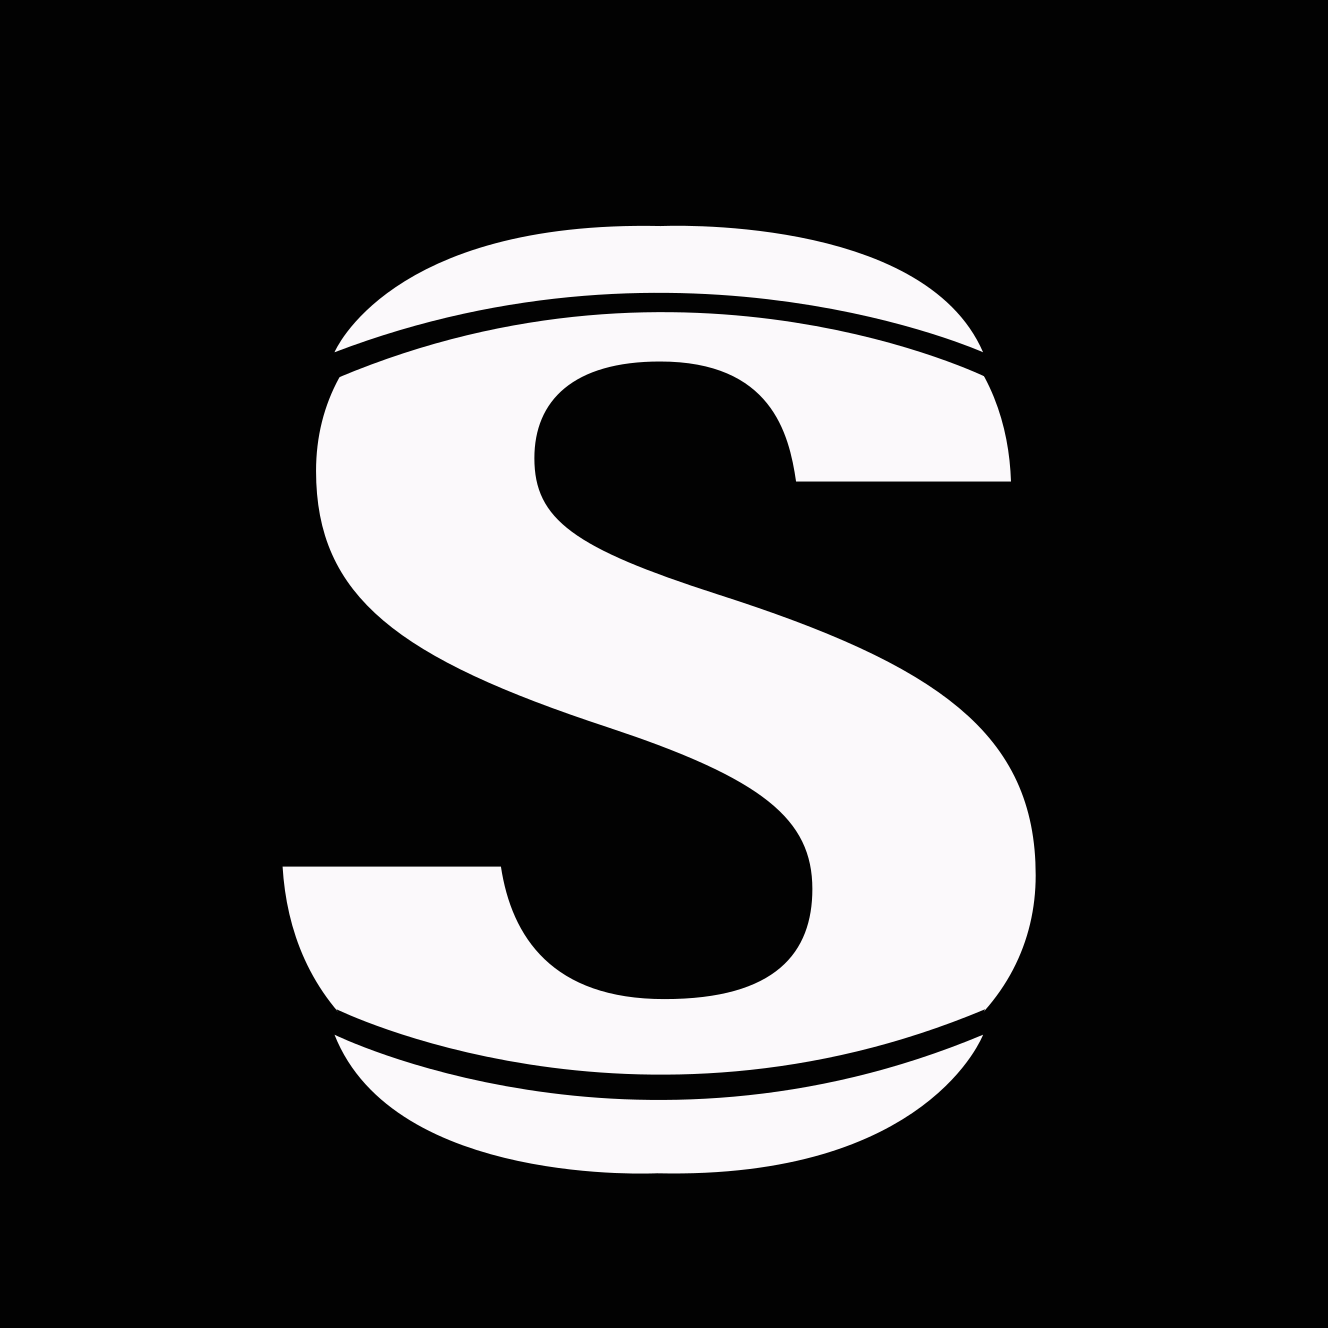

In [2]:
tree = ET.parse("Graphics/GIF/SVG/Asset 4.svg")
root = tree.getroot()
ns = {"svg": "http://www.w3.org/2000/svg"}

rotation_angle = 180

# Find the Arc group
arc_group = root.find(".//svg:g[@id='Arcs']", ns)
cx, cy = 664,664
for path in arc_group.findall(".//svg:path", ns):
    # path.set("transform", f"rotate({rotation_angle}, 664, 664), scale(1,)")  # rotate 15° around center (664,664)
    # transform = (
    #     f"translate({cx},{cy}) "
    #     f"scale(1,1.5) "
    #     f"translate(-{cx},-{cy}) "
    #     f"rotate({rotation_angle}, {cx}, {cy})"
    # )
    transform=(f"rotate({rotation_angle}, {cx}, {cy})"
               f"translate({5},{-62}) ")
    path.set("transform",transform)

tree.write("Graphics/GIF/Temp/Asset 3.svg")
display(SVG(filename="Graphics/GIF/Temp/Asset 3.svg"))


In [3]:
N_frames = 10
rotation_angle = 180
x_translation = np.linspace(0,5,N_frames)
x_translation = np.linspace(0,-62,N_frames)

for n_frame in range(N_frames):
    #Open unmodified file:
    tree = ET.parse("Graphics/GIF/SVG/Asset 4.svg")
    root = tree.getroot()
    ns = {"svg": "http://www.w3.org/2000/svg"}

    # Find the Arc group
    arc_group = root.find(".//svg:g[@id='Arcs']", ns)
    cx, cy = 664,664
    for path in arc_group.findall(".//svg:path", ns):
        transform=(f"rotate({rotation_angle}, {cx}, {cy})"
                f"translate({5},{-62}) ")
        path.set("transform",transform)

    tree.write(f"Graphics/GIF/Frames/{n_frame}.svg")

    drawing = svg2rlg(f"Graphics/GIF/Frames/{n_frame}.svg")
    renderPM.drawToFile(drawing, f"Graphics/GIF/Frames/{n_frame}.png", fmt="PNG")

RenderPMError: cannot import desired renderPM backend rlPyCairo
Seek advice at the users list see
https://pairlist2.pair.net/mailman/listinfo/reportlab-users